<a href="https://colab.research.google.com/github/houmanhaghi/Gold3n-mind/blob/AI-Estimator/gold3n_mind.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pursose**


combination of
  * Buying Au Formula
  * AI Estimation Market

## Buying Au Formula

## AI Estimation Market

In [2]:
! pip install persiantools

In [3]:
import requests
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from persiantools.jdatetime import JalaliDate

In [4]:
url = "https://api.navasan.tech/ohlcSearch/?api_key=freerPVwKRSCRE1qK2YztQ03toKrnDte&item=18ayar&start=1395-01-01&end=1403-09-07"
response = requests.get(url)
data = response.json()

In [5]:
original_data = data.copy()

In [6]:
df = pd.DataFrame(data)
df = df.drop(columns=['timestamp'])
df = df.drop_duplicates(subset='date', keep='first')
df = df.reset_index(drop=True)
df = df.sort_values(by='date')

In [7]:
df['gregorian_date'] = df['date'].apply(lambda x: JalaliDate(int(x[:4]), int(x[5:7]), int(x[8:10])).to_gregorian())
df['gregorian_date'] = pd.to_datetime(df['gregorian_date'])

In [8]:
df.tail()

,date,open,high,low,close,gregorian_date
1967,1403-09-03,4518910,4703820,4518910,4663880,2024-11-23
1968,1403-09-04,4663880,4676120,4521220,4563230,2024-11-24
1969,1403-09-05,4563230,4567620,4466970,4473430,2024-11-25
1970,1403-09-06,4473430,4503210,4440880,4464430,2024-11-26
1971,1403-09-07,4464430,4521450,4464430,4508060,2024-11-27


In [9]:
df.to_csv(f"gold-grm18ayar-iran?start={str(df[df.index==0]['date'])}&end={str(df[df.index==max(df.index)]['date'])}.csv", index=False)

In [10]:
train_data = df[df['date'] < '1402-02-15'][['gregorian_date','close']]
test_data  = df[df['date'] >='1402-02-15'][['gregorian_date','close']]

In [11]:
train_data['gregorian_date'] = pd.to_datetime(train_data['gregorian_date'], errors='coerce')
test_data['gregorian_date'] = pd.to_datetime(test_data['gregorian_date'], errors='coerce')

train_data = train_data.dropna(subset=['gregorian_date'])
test_data = test_data.dropna(subset=['gregorian_date'])

train_data['close'] = pd.to_numeric(train_data['close'], errors='coerce')
test_data['close'] = pd.to_numeric(test_data['close'], errors='coerce')

train_data = train_data.dropna(subset=['close'])
test_data = test_data.dropna(subset=['close'])

In [12]:
train_data.tail()

,gregorian_date,close
1411,2023-04-30,2745050
1412,2023-05-01,2747130
1413,2023-05-02,2721960
1414,2023-05-03,2725660
1415,2023-05-04,2734890


In [13]:
test_data.tail()

,gregorian_date,close
1967,2024-11-23,4663880
1968,2024-11-24,4563230
1969,2024-11-25,4473430
1970,2024-11-26,4464430
1971,2024-11-27,4508060


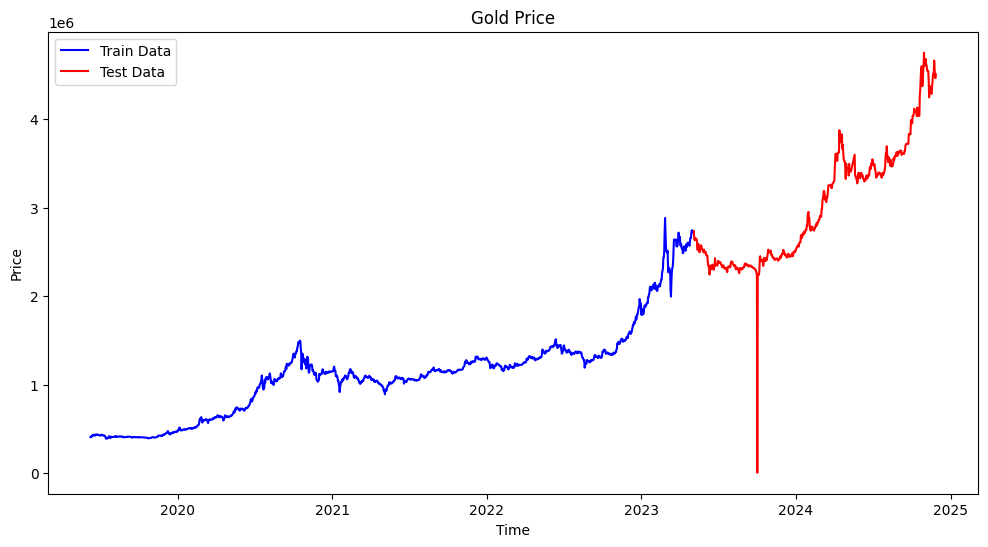

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(train_data['gregorian_date'],
         train_data['close'],
         label='Train Data', color='blue')

plt.plot(test_data['gregorian_date'],
         test_data['close'],
         label='Test Data', color='red')

plt.xlabel('Time')
plt.ylabel('Price')
plt.title('Gold Price')
plt.legend()
plt.show()

In [15]:
if len(test_data) == 0:
    print("The test data is empty. Please check your data download.")
    test_data_scaled = np.array([])
else:
    scaler = MinMaxScaler()
    # Scale only the 'close' column, assuming 'close' is the column you want to scale
    train_data_scaled = scaler.fit_transform(train_data[['close']].values)
    test_data_scaled = scaler.transform(test_data[['close']].values)

In [16]:
lookback = 60  # Number of previous data points to consider
def create_dataset(dataset, look_back=lookback):
    X, Y = [], []
    for i in range(len(dataset)-look_back-1):
        a = dataset[i:(i+look_back), 0]
        X.append(a)
        Y.append(dataset[i + look_back, 0])
    return np.array(X), np.array(Y)

X_train, y_train = create_dataset(train_data_scaled)
X_test, y_test = create_dataset(test_data_scaled)

X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))


In [17]:
class LSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(LSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])
        return out

input_dim = 1
hidden_dim = 50
num_layers = 1
output_dim = 1
model = LSTM(input_dim, hidden_dim, num_layers, output_dim)

loss_fn = torch.nn.MSELoss()
optimiser = torch.optim.Adam(model.parameters(), lr=0.01)


In [18]:
num_epochs = 100
X_train_tensor = torch.from_numpy(X_train).type(torch.Tensor)
y_train_tensor = torch.from_numpy(y_train).type(torch.Tensor)
for t in range(num_epochs):
    y_train_pred = model(X_train_tensor)
    loss = loss_fn(y_train_pred, y_train_tensor.view(-1, 1))
    optimiser.zero_grad()
    loss.backward()
    optimiser.step()

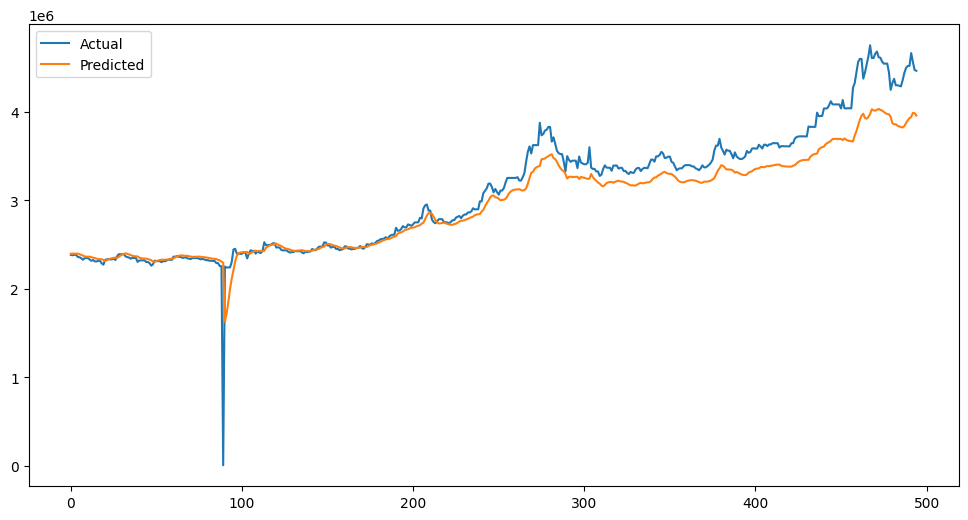

In [19]:
X_test_tensor = torch.from_numpy(X_test).type(torch.Tensor)
y_test_pred = model(X_test_tensor)

y_test_pred = scaler.inverse_transform(y_test_pred.detach().numpy())
y_test = scaler.inverse_transform([y_test])
plt.figure(figsize=(12,6))
plt.plot(y_test[0], label='Actual')
plt.plot(y_test_pred, label='Predicted')
plt.legend()
plt.show()